# TG4DAC: language models planning WarpSpeed kernels

On an RTX PRO 6000 Blackwell, a Gemma 4 31B **planner** proposed what to change, a Gemma 4 31B **refiner** turned the
proposal into a WarpSpeed plan checked by `warpspeed_check`, and a frontier model implemented the plan as written.
Attention was held out of the refiner's training, so these are results on unseen work. Each design was timed against
vLLM's kernel in the same run [M].

**Evidence and execution:** Recorded SM120 attention and end-to-end studies; operator latency and model throughput have different scopes.

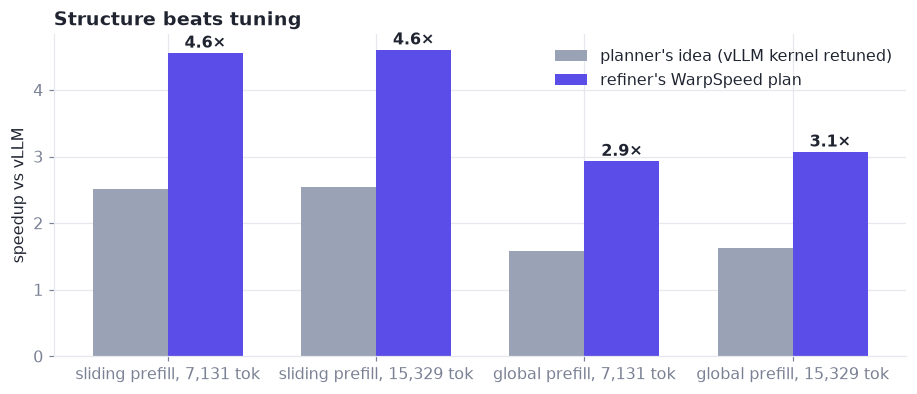

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
tg = pd.read_csv(DATA / "tg4dac_attention.csv")
pre = tg[tg.phase == "prefill"]
fig, ax = plt.subplots(figsize=(10, 3.8))
lab = [f"{l} prefill, {m:,} tok" for l, m in zip(pre.layer, pre.M)]; x = np.arange(len(pre)); wd = 0.36
ax.bar(x - wd / 2, pre.vllm_ms / pre.planner_ms, wd, color=C["ref"], label="planner's idea (vLLM kernel retuned)")
ax.bar(x + wd / 2, pre.vllm_ms / pre.refiner_warpspeed_ms, wd, color=C["ours"], label="refiner's WarpSpeed plan")
for i, v in enumerate(pre.vllm_ms / pre.refiner_warpspeed_ms): ax.text(i + wd / 2, v + 0.08, f"{v:.1f}×", ha="center", fontweight="bold")
ax.set_xticks(x, lab); ax.set_ylabel("speedup vs vLLM"); ax.legend(loc="upper right"); ax.set_title("Structure beats tuning")
save(fig, "tg4dac_prefill"); plt.show()

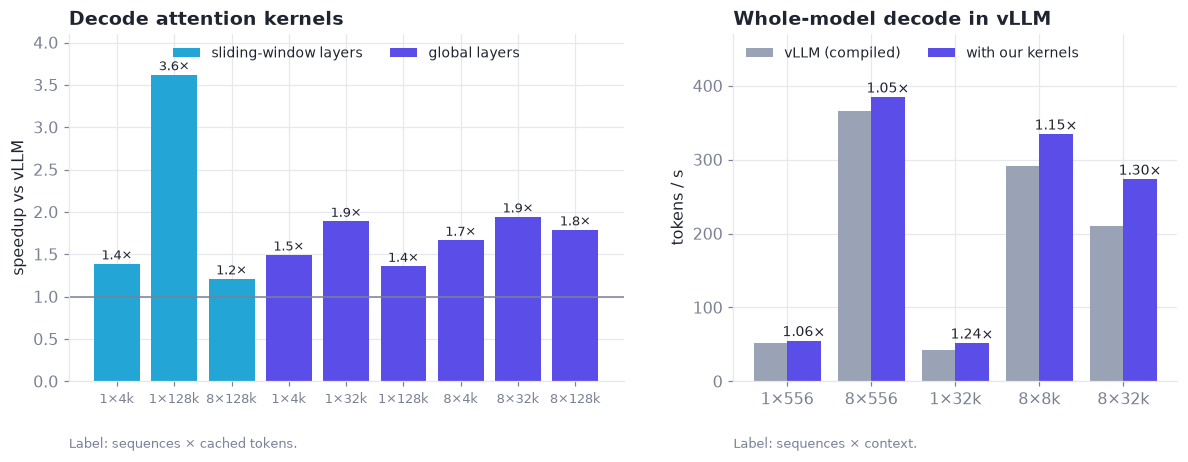

In [2]:
dec = tg[tg.phase == "decode"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.1), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.22})
k = lambda c: f"{c // 1024}k"
sp = dec.vllm_ms / dec.refiner_warpspeed_ms
axes[0].bar(range(len(dec)), sp, color=[C["cyan"] if l == "sliding" else C["ours"] for l in dec.layer])
for i, v in enumerate(sp): axes[0].text(i, v + 0.05, f"{v:.1f}×", ha="center", fontsize=8.5)
axes[0].set_xticks(range(len(dec)), [f"{m}×{k(c)}" for m, c in zip(dec.M, dec.context.astype(int))], fontsize=8.5)
axes[0].axhline(1, color=MUTED, lw=1); axes[0].set_ylim(0, 4.1); axes[0].set_ylabel("speedup vs vLLM")
axes[0].bar([0], [0], color=C["cyan"], label="sliding-window layers"); axes[0].bar([0], [0], color=C["ours"], label="global layers")
axes[0].legend(loc="upper center", ncol=2, fontsize=9); axes[0].set_title("Decode attention kernels")
note(axes[0], "Label: sequences × cached tokens.")
e2e = pd.read_csv(DATA / "tg4dac_e2e.csv")
lab = [f"{s}×{c // 1024 if c >= 1024 else c}{'k' if c >= 1024 else ''}" for s, c in zip(e2e.sequences, e2e.context)]
axes[1].bar(np.arange(len(e2e)) - 0.2, e2e.vllm_tok_s, 0.4, color=C["ref"], label="vLLM (compiled)")
axes[1].bar(np.arange(len(e2e)) + 0.2, e2e.ours_tok_s, 0.4, color=C["ours"], label="with our kernels")
for i, (a, b) in enumerate(zip(e2e.vllm_tok_s, e2e.ours_tok_s)): axes[1].text(i + 0.2, b + 6, f"{b / a:.2f}×", ha="center", fontsize=9)
axes[1].set_xticks(range(len(e2e)), lab); axes[1].set_ylabel("tokens / s"); axes[1].set_ylim(0, 470)
axes[1].legend(loc="upper left", ncol=2, fontsize=9); axes[1].set_title("Whole-model decode in vLLM")
note(axes[1], "Label: sequences × context.")
save(fig, "tg4dac_decode"); plt.show()

**Why the end-to-end gain is smaller than the kernel gain.** Every decode step pays about 18 ms that attention
doesn't touch (the weights of the projections, the MLP, the adapters and the output layer). Attention grows with
context, so the speedup grows with context too: 1.06× at short context, 1.30× at 8 × 32k.

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)